# Test Data Analysis Tools

This notebook will be used to explore basic functionality of CSV data import and handling followed by the plotting of time series data.
Here aer some assumptions we will use to start:
- The CSV contains one measurement per row.
- Each measurement channel occupies one column.
- A time variable is present, preferably in seconds.
- Measurement channels contain numeric data.
- The CSV has a header row containing the column names.

### Import Packages

In [68]:
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from matplotlib.backends.backend_pdf import PdfPages

import math

import ipywidgets as widgets

from IPython.display import display, clear_output
from matplotlib.ticker import StrMethodFormatter

### Set plotting style

In [53]:
sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep",
)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["axes.labelsize"] = 10
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["font.size"] = 9


### Configure the Input File

In [54]:
PROJECT_DIR = Path("..")

INPUT_DIR = PROJECT_DIR / "data" / "input"
OUTPUT_DIR = PROJECT_DIR / "data" / "output"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CSV_FILE = INPUT_DIR / "simulated_sensor_data.csv"
TIME_COLUMN = None

### Import the CSV

In [55]:
def import_csv(file_path):

    file_path = Path(file_path)

    if not file_path.exists():
        raise FileNotFoundError(f"File not found: {file_path}"
        )

    df = pd.read_csv(file_path)

    if df.empty:
        raise ValueError(f"CSV file contains no data.")

    if len(df.columns) == 0:
        raise ValueError(f"CSV file contains no columns.")

     # Remove accidental whitespace from column names
    df.columns = df.columns.astype(str).str.strip()

    return df

In [56]:
df = import_csv(CSV_FILE)

print(f"File imported successfully: {CSV_FILE.name}")
print(f"Number of samples: {len(df)}")
print(f"Number of columns: {len(df.columns)}")

File imported successfully: simulated_sensor_data.csv
Number of samples: 600
Number of columns: 15


### Identify the Time Column
We want to be able to identify the time data column in case it is not the first column.


In [57]:
def identify_time_column(df, requested_column=None):

    if requested_column is not None:

        if requested_column not in df.columns:
            raise ValueError(
                f"Time column '{requested_column}' not found."
            )

        return requested_column

    candidates = [
        "time",
        "time (s)",
        "time_s",
        "timestamp",
        "elapsed time",
        "elapsed_time",
        "test time",
        "test_time",
        "seconds"
    ]

    normalized_columns = {
        str(column).strip().lower(): column
        for column in df.columns
    }

    for candidate in candidates:

        if candidate in normalized_columns:
            return normalized_columns[candidate]

    return None

### Identify Numeric Channels

In [58]:
def identify_numeric_channels(df, time_column=None):

    numeric_columns = df.select_dtypes(
        include=[np.number]
    ).columns.tolist()

    if time_column in numeric_columns:
        numeric_columns.remove(time_column)

    return numeric_columns

### Horizontal Axis

In [59]:
def prepare_time_axis(df, time_column):

    if time_column is None:

        return (
            np.arange(len(df)),
            "Sample Number",
            False
        )

    raw_time = df[time_column]

    numeric_time = pd.to_numeric(
        raw_time,
        errors="coerce"
    )

    if numeric_time.notna().mean() >= 0.8:

        return (
            numeric_time,
            time_column,
            False
        )

    datetime_time = pd.to_datetime(
        raw_time,
        errors="coerce",
        format="mixed"
    )

    if datetime_time.notna().mean() >= 0.8:

        return (
            datetime_time,
            time_column,
            True
        )

    print(
        "Warning: Time column could not be interpreted. "
        "Using sample number instead."
    )

    return (
        np.arange(len(df)),
        "Sample Number",
        False
    )

## Data Manager

In [60]:

def create_test_data(df, filename, time_column=None):

    # Identify the time variable
    time_column = identify_time_column(
        df,
        time_column
    )

    # Identify numeric measurement channels
    channels = identify_numeric_channels(
        df,
        time_column
    )

    # Prepare horizontal axis
    time_values, time_label, is_datetime = prepare_time_axis(
        df,
        time_column
    )

    # Create central data object
    test_data = {
        "dataframe": df,
        "filename": filename,
        "time_column": time_column,
        "time_values": time_values,
        "time_label": time_label,
        "is_datetime": is_datetime,
        "channels": channels,
        "number_of_samples": len(df),
        "number_of_channels": len(channels)
    }

    return test_data


In [61]:
test_data = create_test_data(
    df=df,
    filename=CSV_FILE.name,
    time_column=TIME_COLUMN
)

print(f"Filename: {test_data['filename']}")
print(f"Samples: {test_data['number_of_samples']}")
print(f"Channels: {test_data['number_of_channels']}")
print(f"Time variable: {test_data['time_column']}")

print("\nAvailable channels:")

for channel in test_data["channels"]:
    print(f" - {channel}")

Filename: simulated_sensor_data.csv
Samples: 600
Channels: 14
Time variable: Time_s

Available channels:
 - Temperature_C
 - Pressure_bar
 - Flow_L_min
 - Vibration_mm_s
 - Voltage_V
 - Current_A
 - Humidity_pct
 - Speed_RPM
 - Torque_Nm
 - Acceleration_m_s2
 - Displacement_mm
 - Power_kW
 - Conductivity_mS
 - Level_pct


### Inspect the Data

In [62]:
def inspect_data(df):

    print("COLUMN INFORMATION")
    print("-" * 50)

    for column in df.columns:

        print(
            f"{column:<30} "
            f"{df[column].dtype}"
        )

    print("\nDATA SUMMARY")
    print("-" * 50)

    display(df.describe(include="all").T)

    print("\nFIRST 5 SAMPLES")
    print("-" * 50)

    display(df.head())

In [63]:
inspect_data(df)

COLUMN INFORMATION
--------------------------------------------------
Time_s                         int64
Temperature_C                  float64
Pressure_bar                   float64
Flow_L_min                     float64
Vibration_mm_s                 float64
Voltage_V                      float64
Current_A                      float64
Humidity_pct                   float64
Speed_RPM                      float64
Torque_Nm                      float64
Acceleration_m_s2              float64
Displacement_mm                float64
Power_kW                       float64
Conductivity_mS                float64
Level_pct                      float64

DATA SUMMARY
--------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
Time_s,600.0,299.500000,173.349358,0.0000,149.750000,299.50000,449.250000,599.0000
Temperature_C,600.0,25.725483,1.829365,22.1700,24.020000,25.81500,27.402500,29.3600
Pressure_bar,600.0,5.372987,0.294019,4.8670,5.111000,5.37650,5.621500,5.9730
Flow_L_min,600.0,123.295817,11.073653,100.8400,113.470000,123.39500,133.232500,145.1900
Vibration_mm_s,600.0,3.809000,0.746921,2.2020,3.160250,3.85650,4.470250,5.2630
Voltage_V,600.0,230.322950,1.456287,227.6000,228.967500,230.29500,231.675000,233.1100
Current_A,600.0,12.145015,1.091759,10.2430,11.118750,12.17850,13.179750,14.0770
Humidity_pct,600.0,45.868167,3.885993,37.1000,42.400000,46.30000,49.400000,52.3000
Speed_RPM,600.0,1513.622833,57.341002,1399.3000,1460.600000,1512.10000,1564.425000,1627.9000
Torque_Nm,600.0,88.305100,8.773526,69.0100,80.287500,88.06500,96.285000,104.7500



FIRST 5 SAMPLES
--------------------------------------------------


,Time_s,Temperature_C,Pressure_bar,Flow_L_min,Vibration_mm_s,Voltage_V,Current_A,Humidity_pct,Speed_RPM,Torque_Nm,Acceleration_m_s2,Displacement_mm,Power_kW,Conductivity_mS,Level_pct
0,0,24.94,5.112,122.61,3.559,229.80,12.029,46.0,1485.0,86.16,-0.5341,9.559,17.81,1.7668,65.67
1,1,25.29,5.213,126.69,3.661,229.58,12.323,46.3,1500.0,89.95,0.0986,9.866,17.38,1.8343,65.99
2,2,25.23,5.211,126.55,3.909,230.00,12.619,46.8,1511.7,91.70,0.2633,10.063,18.44,1.8989,67.12
3,3,25.44,5.213,129.76,4.086,230.13,12.780,46.6,1517.4,95.50,0.2023,10.101,18.81,1.9360,69.17
4,4,25.91,5.240,130.33,4.036,230.40,12.900,47.2,1521.8,94.51,0.7150,10.388,19.20,1.9362,69.63


## Generate Time Histories

For this first version here are the assumptions we will use to keep it simple.

1. Each measurement channel gets its own plot.
2. All plots use the same horizontal time axis.
3. Each channel has an independent vertical axis.
4. The vertical axis is automatically scaled to the available data.
5. Plots are arranged four per PDF page.


### Create Plotting Function

In [89]:
from IPython.display import display


def plot_time_histories(
    test_data,
    selected_channels=None,
    plots_per_page=4,
    page_orientation="landscape",
    custom_title=None,
    show_grid=True,
    y_axis_limits=None
):

    df = test_data["dataframe"]
    time_values = test_data["time_values"]
    time_label = test_data["time_label"]
    is_datetime = test_data["is_datetime"]

    # Default: plot all available channels
    if selected_channels is None:
        selected_channels = test_data["channels"]

    # Validate selected channels
    invalid_channels = [
        channel for channel in selected_channels
        if channel not in test_data["channels"]
    ]

    if invalid_channels:
        raise ValueError(
            f"Invalid channels selected: {invalid_channels}"
        )

    # Validate plotting configuration
    if plots_per_page not in [1, 2, 4, 6]:
        raise ValueError("Invalid plots per page setting.")

    if page_orientation not in ["landscape", "portrait"]:
        raise ValueError("Invalid page orientation.")

    # Exclude channels without sufficient valid data
    valid_channels = [
        channel for channel in selected_channels
        if pd.to_numeric(
            df[channel],
            errors="coerce"
        ).notna().sum() >= 2
    ]

    if not valid_channels:
        raise ValueError("No valid numeric measurement channels selected.")

     # A4 dimensions in inches
    if page_orientation == "landscape":
        figsize = (11.69, 8.27)
    else:
        figsize = (8.27, 11.69)

    # Automatic subplot arrangement
    layouts = {
        "landscape": {
            1: (1, 1),
            2: (1, 2),
            4: (2, 2),
            6: (2, 3)
        },
        "portrait": {
            1: (1, 1),
            2: (2, 1),
            4: (2, 2),
            6: (3, 2)
        }
    }

    nrows, ncols = layouts[page_orientation][plots_per_page]

    figures = []

    pages = math.ceil(
        len(valid_channels) / plots_per_page
    )


    # Generate plots
    for page in range(pages):

        start = page * plots_per_page
        end = start + plots_per_page

        page_channels = valid_channels[start:end]

        fig, axes = plt.subplots(
            nrows,
            ncols,
            figsize=figsize,
            sharex=True
        )

        axes = np.array(axes, dtype=object).flatten()

        for ax, channel in zip(axes, page_channels):

            y = pd.to_numeric(
                df[channel],
                errors="coerce"
            )

            ax.plot(
                time_values,
                y,
                linewidth=0.8
            )

            ax.set_title(channel)
            ax.set_ylabel(channel)
            ax.set_xlabel(time_label)

            if show_grid:
                ax.grid(True, alpha=0.35)
            else:
                ax.grid(False)

            ax.margins(x=0.01)

            # Apply manual Y-axis limits if configured
            if y_axis_limits and channel in y_axis_limits:

                lower, upper = y_axis_limits[channel]

                if (
                    not np.isfinite(lower)
                    or not np.isfinite(upper)
                    or lower >= upper
                ):
                    raise ValueError(
                        f"Invalid Y-axis limits for {channel}."
                    )

                ax.set_ylim(lower, upper)

            # Configure time axis
            if is_datetime:

                ax.xaxis.set_major_formatter(
                    mdates.DateFormatter("%H:%M:%S")
                )

                ax.xaxis.set_major_locator(
                    mdates.AutoDateLocator()
                )

            else:

                ax.xaxis.set_major_locator(
                    plt.MaxNLocator(nbins=8)
                )

                ax.xaxis.set_major_formatter(
                    StrMethodFormatter("{x:g}")
                )

            ax.tick_params(
                axis="x",
                labelbottom=True
            )

        # Hide unused subplot positions
        for ax in axes[len(page_channels):]:
            ax.set_visible(False)

        report_title = (
            custom_title.strip()
            if custom_title and custom_title.strip()
            else test_data["filename"]
        )

        fig.suptitle(
            f"{report_title} — Page {page + 1} of {pages}",
            fontsize=14,
            fontweight="bold"
        )

        fig.tight_layout(
            rect=[0, 0, 1, 0.95]
        )

        display(fig)

        figures.append(fig)

    return figures

### Plot all Figures

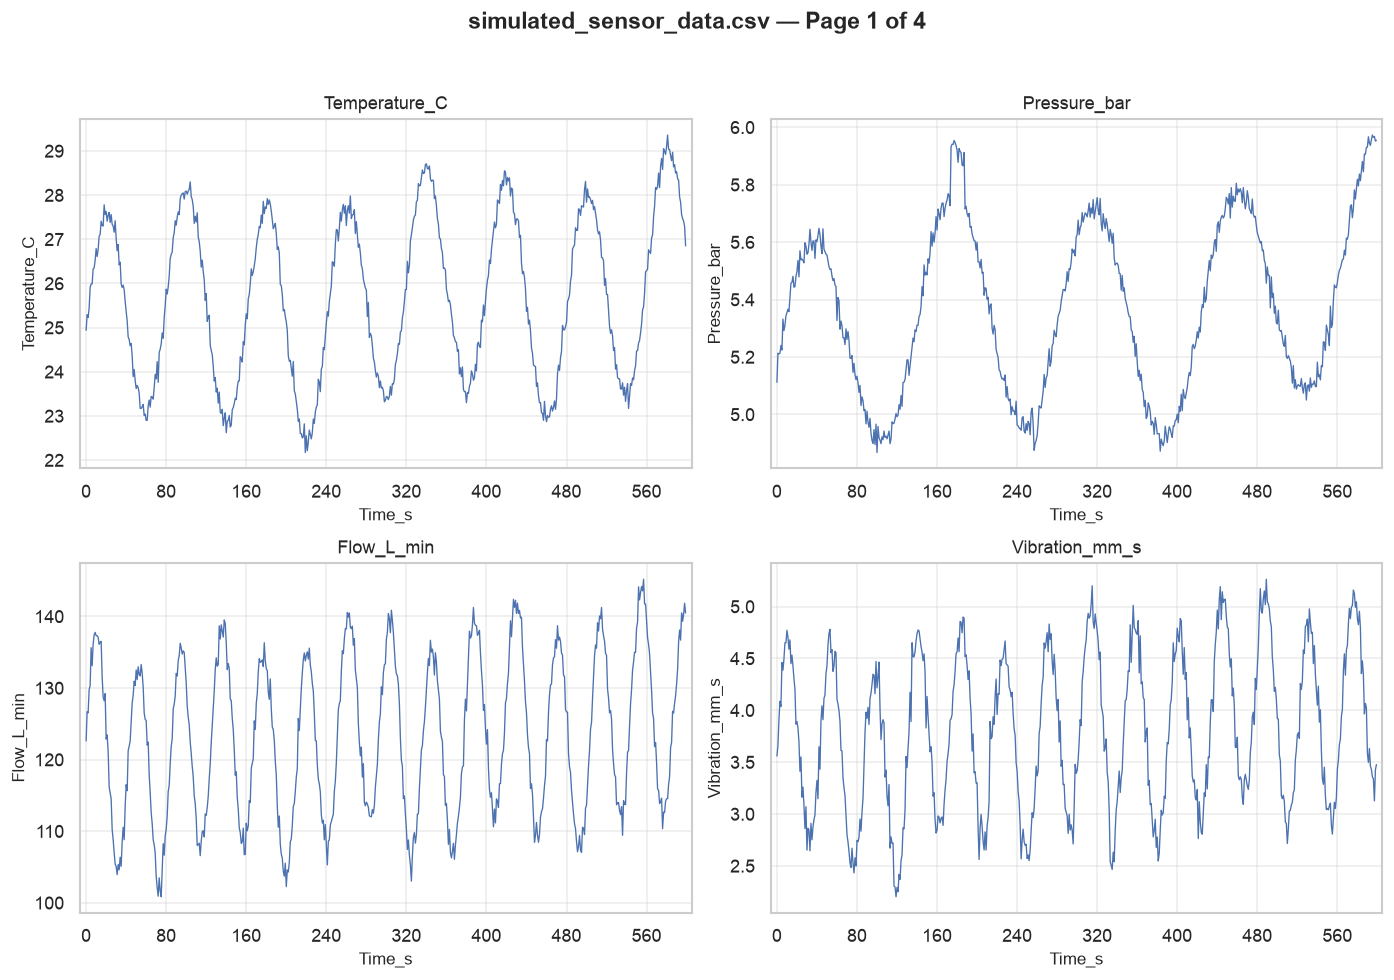

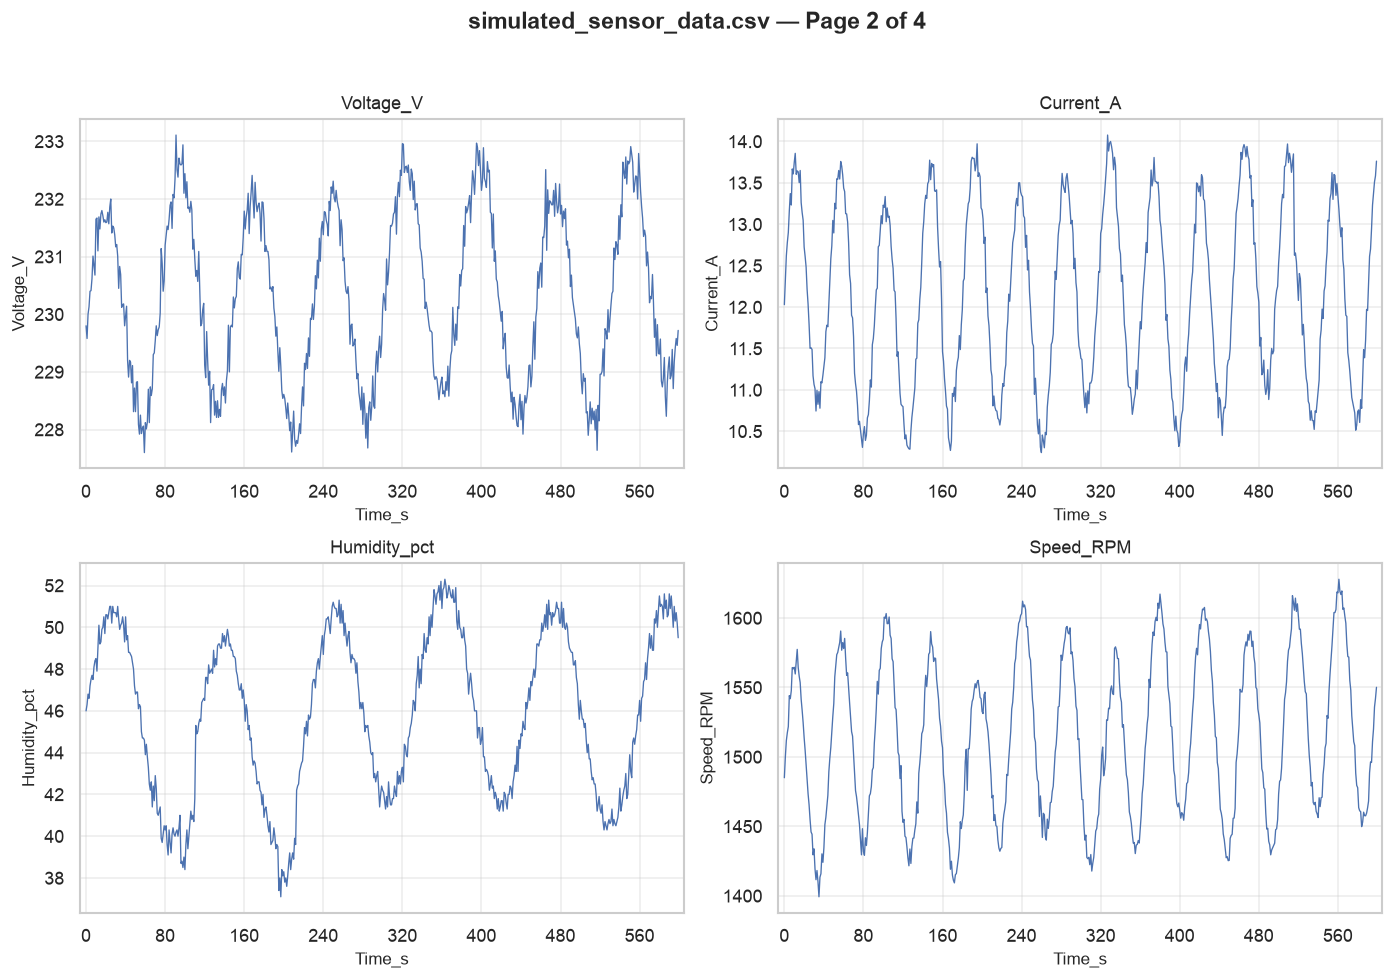

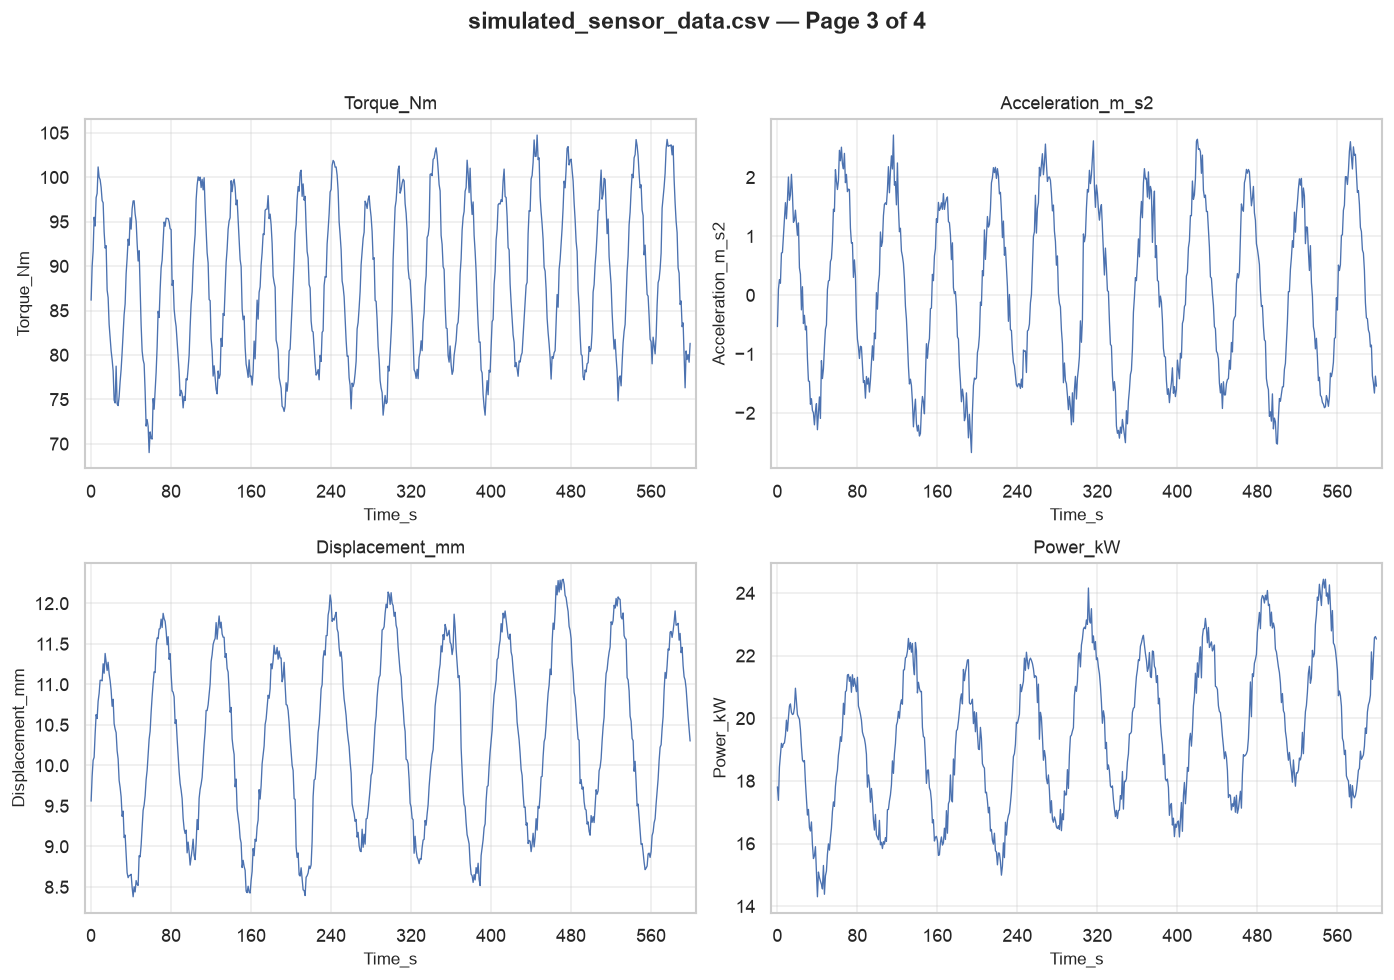

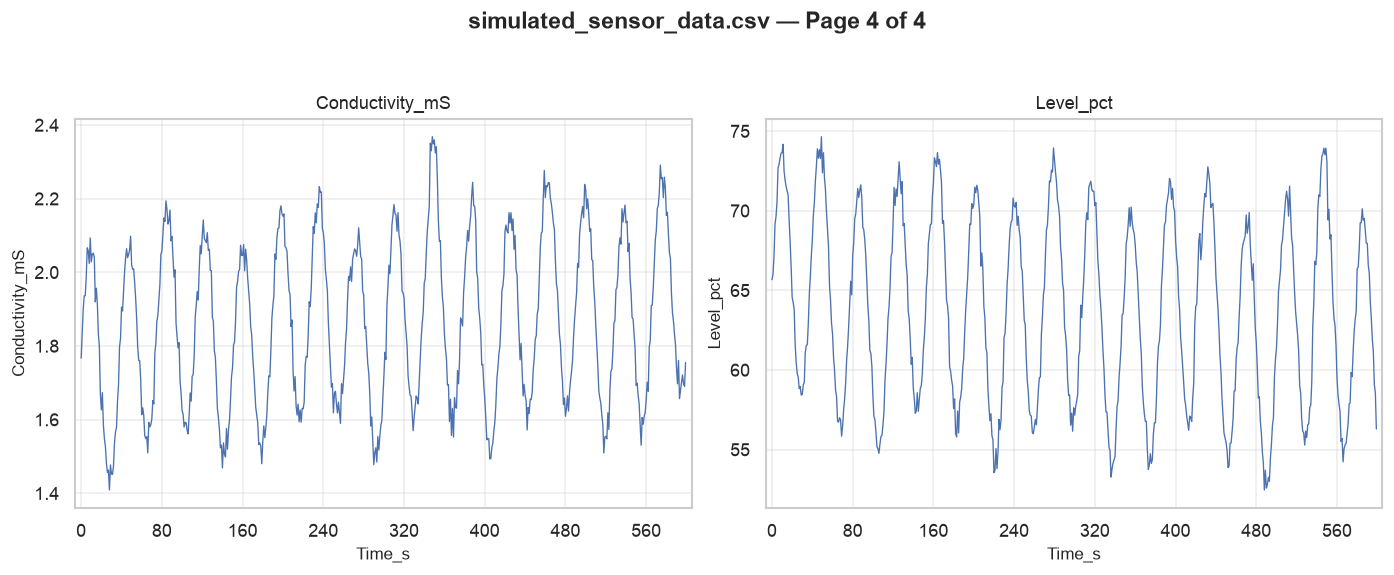

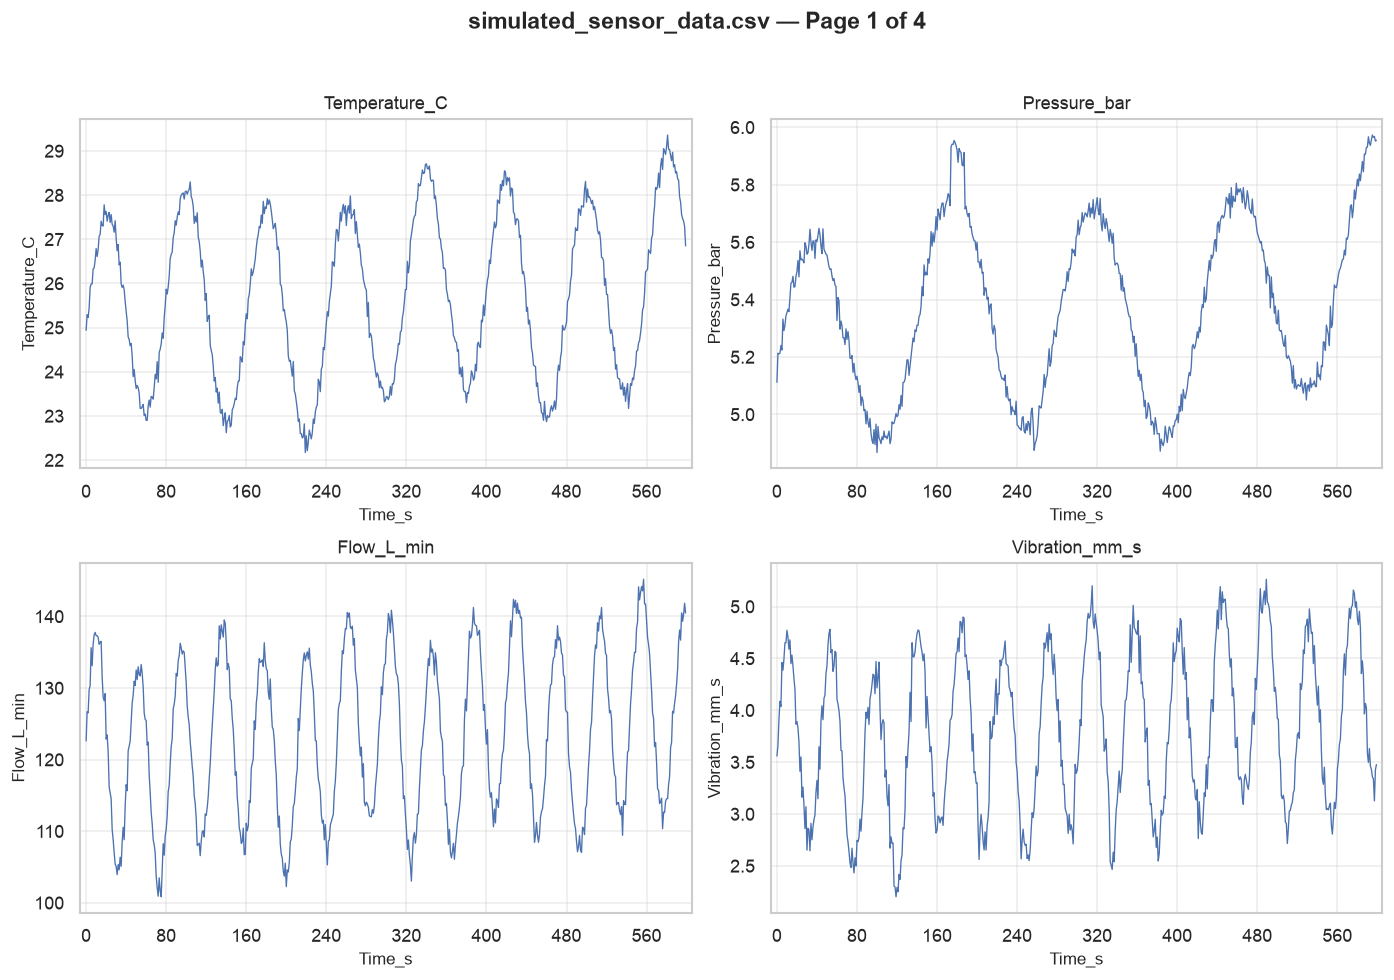

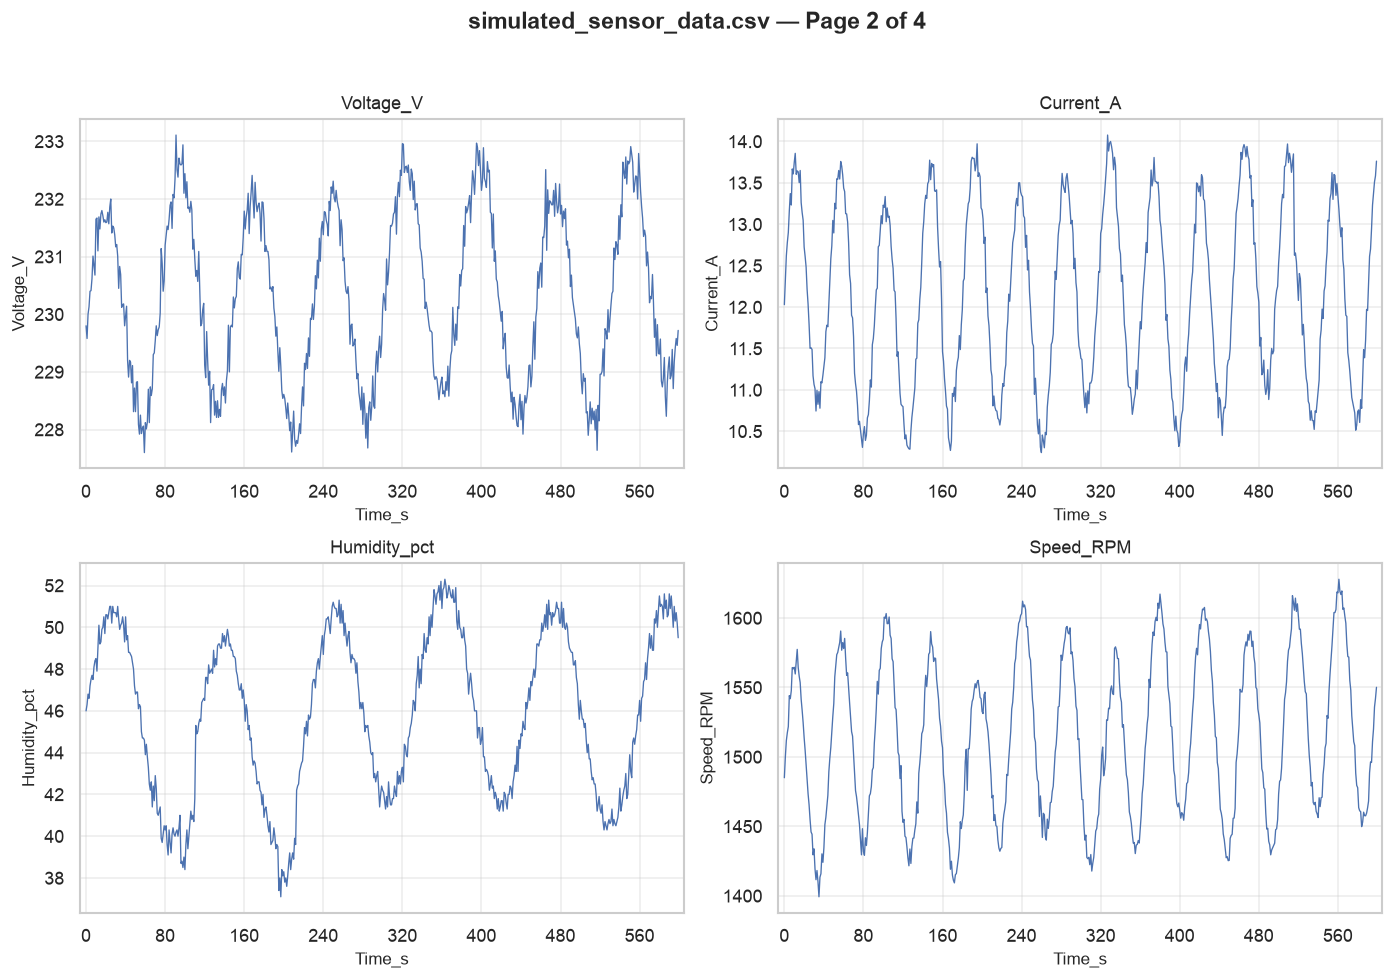

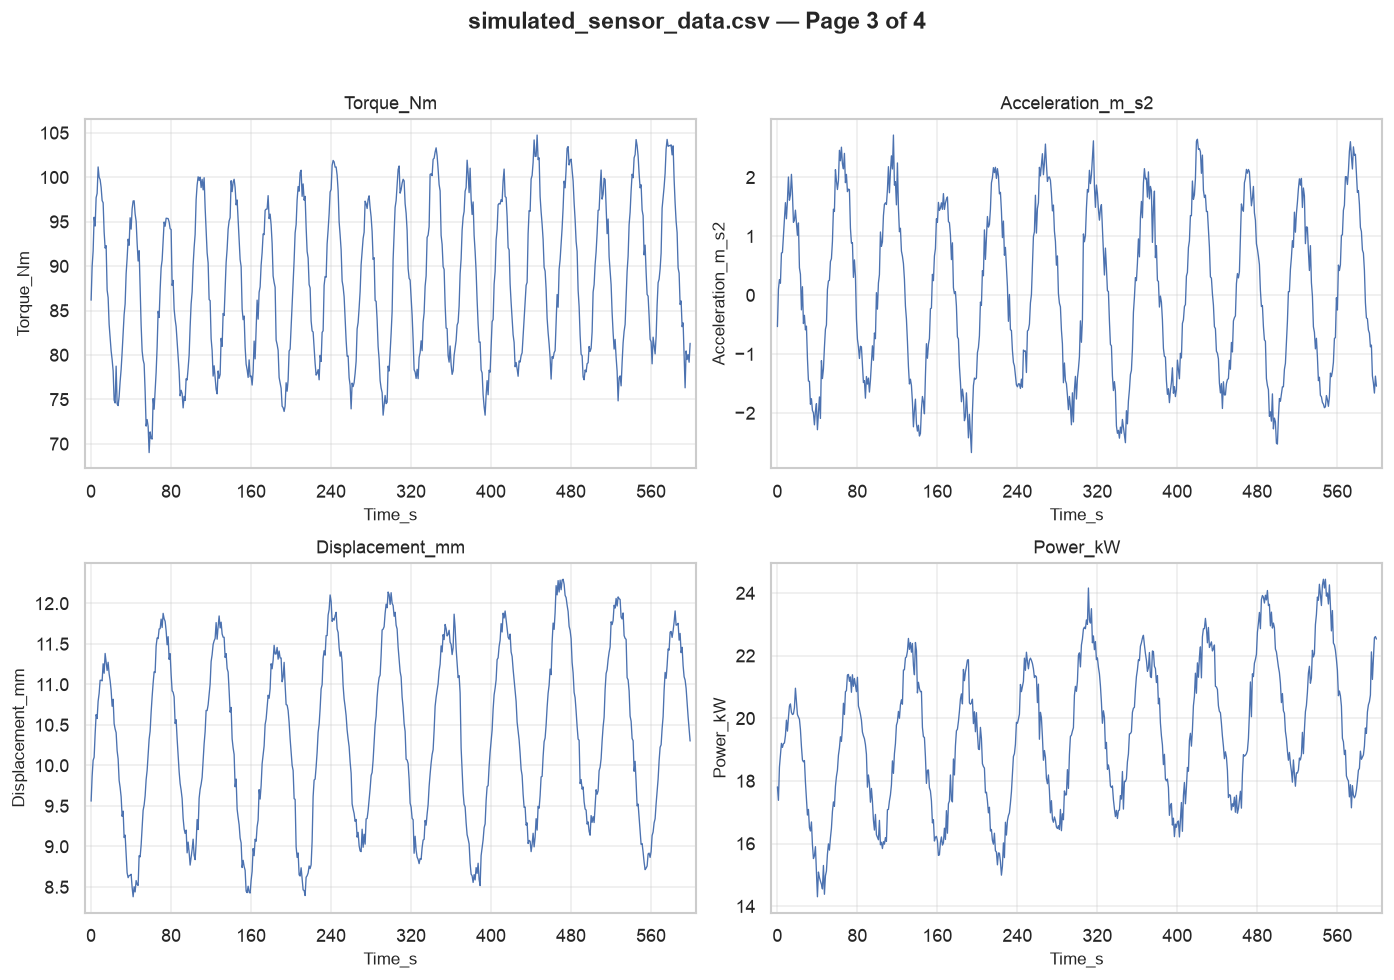

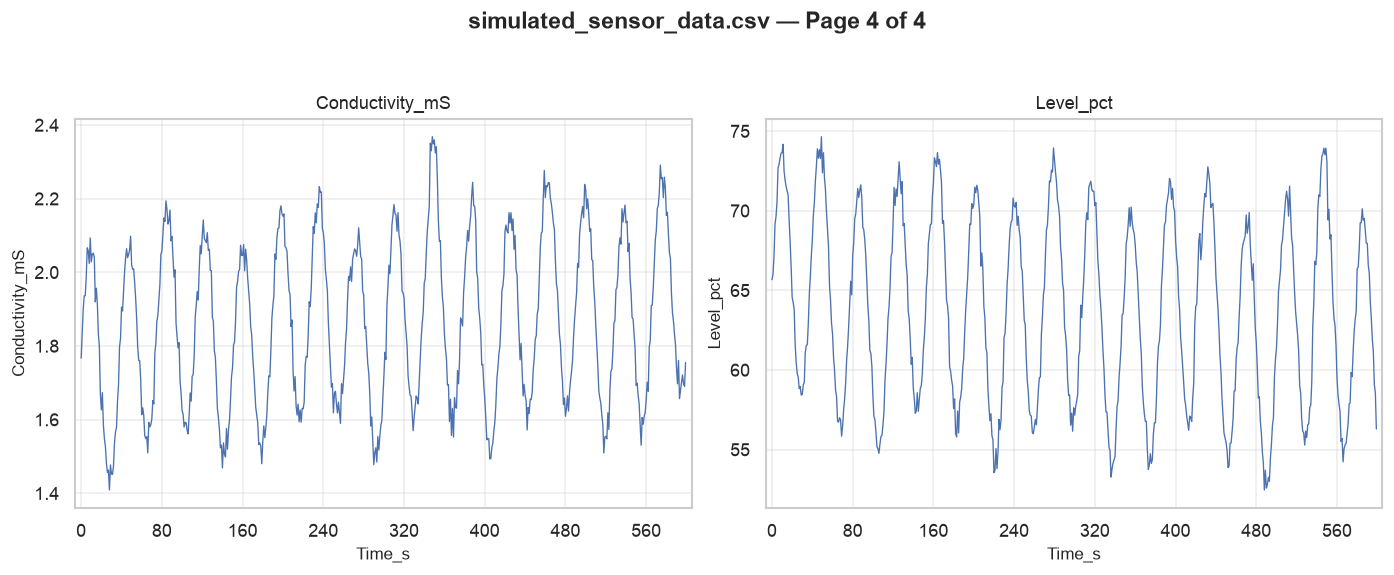

In [72]:
figures = plot_time_histories(
    test_data=test_data
)

### Plot Selected Figures

In [ ]:
figures = plot_time_histories(
    test_data=test_data,
    selected_channels=[
        "Voltage_V",
    ]
)

### Export PDF Report

In [91]:
def export_pdf(
    figures,
    output_file,
    title,
    author,
    subject
):

    if not figures:
        raise ValueError("No figures available for PDF export.")

    output_file = Path(output_file).expanduser()

    if output_file.suffix.lower() != ".pdf":
        output_file = output_file.with_suffix(".pdf")

    output_file.parent.mkdir(parents=True, exist_ok=True)

    with PdfPages(output_file) as pdf:

        for fig in figures:
            pdf.savefig(fig, bbox_inches="tight")

        metadata = pdf.infodict()
        metadata["Title"] = title
        metadata["Author"] = author
        metadata["Subject"] = subject
        metadata["Creator"] = "TestData Analyzer"

    print(f"PDF report generated: {output_file}")

    return output_file

In [74]:
PDF_FILE = OUTPUT_DIR / "test_data_report.pdf"

export_pdf(
    figures=figures,
    output_file=PDF_FILE
)

for fig in figures:
    plt.close(fig)

PDF report generated: ../data/output/test_data_report.pdf


## Interactive Channel Selection

In [75]:
def create_channel_selector(test_data):

    channel_checkboxes = {}

    for channel in test_data["channels"]:

        channel_checkboxes[channel] = widgets.Checkbox(
            value=True,
            description=channel,
            indent=False,
            layout=widgets.Layout(
                width="300px"
            )
        )
    return channel_checkboxes

In [76]:
channel_checkboxes = create_channel_selector(test_data)

### Create Select All and Deselect All controls

In [77]:
select_all_button = widgets.Button(
    description="Select All",
    button_style="info",
    icon="check-square"
)

deselect_all_button = widgets.Button(
    description="Deselect All",
    button_style="warning",
    icon="square"
)

In [78]:
# Callback functions
def select_all_channels(button):

    for checkbox in channel_checkboxes.values():
        checkbox.value = True


def deselect_all_channels(button):

    for checkbox in channel_checkboxes.values():
        checkbox.value = False

In [79]:
# Onclick Actions

select_all_button.on_click(
    select_all_channels
)

deselect_all_button.on_click(
    deselect_all_channels
)

### Generate Plots Button

In [80]:
# Create button

generate_plots_button = widgets.Button(
    description="Generate Plots",
    button_style="success",
    icon="line-chart",
    layout=widgets.Layout(
        width="200px",
        height="40px"
    )
)

In [81]:
plot_output = widgets.Output()

plot_state = {
    "figures": []
}

In [82]:
# Plot button callback

def generate_selected_plots(button):

    selected_channels = [
        channel
        for channel, checkbox in channel_checkboxes.items()
        if checkbox.value
    ]

    with plot_output:

        clear_output(wait=True)

        if not selected_channels:
            print("Please select at least one measurement channel.")
            return

        # Collect manual Y-axis limits
        y_axis_limits = {}

        for channel in selected_channels:

            controls = axis_limit_controls[channel]

            if controls["enabled"].value:

                lower = controls["min"].value
                upper = controls["max"].value

                if (
                    not np.isfinite(lower)
                    or not np.isfinite(upper)
                    or lower >= upper
                ):
                    print(
                        f"Invalid Y-axis limits for {channel}. "
                        "Minimum must be less than maximum."
                    )
                    return

                y_axis_limits[channel] = (lower, upper)

        # Close previously generated figures
        for fig in plot_state["figures"]:
            plt.close(fig)

        try:

            figures = plot_time_histories(
                test_data=test_data,
                selected_channels=selected_channels,
                plots_per_page=plots_per_page_widget.value,
                page_orientation=orientation_widget.value,
                custom_title=title_widget.value,
                show_grid=grid_widget.value,
                y_axis_limits=y_axis_limits
            )

            plot_state["figures"] = figures

        except ValueError as error:

            print(f"Plot configuration error: {error}")

In [83]:
# Onclick for plot button

generate_plots_button.on_click(
    generate_selected_plots
)

## Build an Interface

### Plot Configuration

#### Layout Controls

In [84]:

plots_per_page_widget = widgets.Dropdown(
    options=[1, 2, 4, 6],
    value=4,
    description="Plots per page:",
    style={"description_width": "initial"}
)

orientation_widget = widgets.Dropdown(
    options=[
        ("A4 Landscape", "landscape"),
        ("A4 Portrait", "portrait")
    ],
    value="landscape",
    description="Page orientation:",
    style={"description_width": "initial"}
)

grid_widget = widgets.Checkbox(
    value=True,
    description="Display plot grid",
    indent=False
)

title_widget = widgets.Text(
    value="Test Data Analysis Report",
    description="Report title:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="450px")
)

#### Y-Axis Configuration

In [85]:
def create_axis_limit_controls(test_data):

    axis_controls = {}
    accordion_contents = []

    df = test_data["dataframe"]

    for channel in test_data["channels"]:

        values = pd.to_numeric(
            df[channel],
            errors="coerce"
        ).dropna()

        data_min = float(values.min())
        data_max = float(values.max())

        data_range = data_max - data_min

        padding = (
            data_range * 0.05
            if data_range > 0
            else max(abs(data_min) * 0.05, 1.0)
        )

        manual_checkbox = widgets.Checkbox(
            value=False,
            description="Enable manual Y-axis limits",
            indent=False
        )

        min_widget = widgets.FloatText(
            value=data_min - padding,
            description="Y minimum:",
            disabled=True,
            layout=widgets.Layout(width="220px")
        )

        max_widget = widgets.FloatText(
            value=data_max + padding,
            description="Y maximum:",
            disabled=True,
            layout=widgets.Layout(width="220px")
        )

        def toggle_limits(change, min_control=min_widget,
                          max_control=max_widget):

            enabled = change["new"]

            min_control.disabled = not enabled
            max_control.disabled = not enabled

        manual_checkbox.observe(
            toggle_limits,
            names="value"
        )

        axis_controls[channel] = {
            "enabled": manual_checkbox,
            "min": min_widget,
            "max": max_widget
        }

        channel_controls = widgets.VBox([
            manual_checkbox,
            widgets.HBox([
                min_widget,
                max_widget
            ])
        ])

        accordion_contents.append(channel_controls)

    accordion = widgets.Accordion(
        children=accordion_contents
    )

    for index, channel in enumerate(test_data["channels"]):
        accordion.set_title(index, channel)

    return axis_controls, accordion

In [86]:
axis_limit_controls, axis_limit_accordion = (
    create_axis_limit_controls(test_data)
)

### Export Configuration Widgets

In [90]:
pdf_directory_widget = widgets.Text(
    value=str(OUTPUT_DIR),
    description="Output folder:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="600px")
)

pdf_filename_widget = widgets.Text(
    value="test_data_analysis_report.pdf",
    description="PDF filename:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="450px")
)

pdf_title_widget = widgets.Text(
    value="Test Data Analysis Report",
    description="Document title:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="450px")
)

pdf_author_widget = widgets.Text(
    value="TestData Analyzer",
    description="Author:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="450px")
)

pdf_subject_widget = widgets.Text(
    value="Time History Plots",
    description="Subject:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="450px")
)

#### Export Button and Output Area

In [94]:
export_pdf_button = widgets.Button(
    description="Export PDF",
    button_style="success",
    icon="file-pdf",
    layout=widgets.Layout(width="200px", height="40px")
)

pdf_export_output = widgets.Output()

#### Export Callback

In [95]:
def export_configured_pdf(button):

    with pdf_export_output:
        clear_output(wait=True)

        if not plot_state["figures"]:
            print("Please generate plots before exporting.")
            return

        directory = pdf_directory_widget.value.strip()
        filename = pdf_filename_widget.value.strip()

        if not directory:
            print("Please specify an output directory.")
            return

        if not filename:
            print("Please specify a PDF filename.")
            return

        output_file = Path(directory).expanduser() / filename

        try:
            exported_file = export_pdf(
                figures=plot_state["figures"],
                output_file=output_file,
                title=pdf_title_widget.value,
                author=pdf_author_widget.value,
                subject=pdf_subject_widget.value
            )

            print(f"Export location: {exported_file.resolve()}")

        except (ValueError, OSError) as error:
            print(f"PDF export error: {error}")


export_pdf_button.on_click(export_configured_pdf)

### Interface Assembly

In [102]:
# Channel selection heading
channel_heading = widgets.HTML(
    value="<h3>Measurement Channel Selection</h3>"
)

# Arrange checkboxes into a vertical container
channel_list = widgets.VBox(
    list(channel_checkboxes.values()),
    layout=widgets.Layout(
        max_height="300px",
        overflow_y="auto",
        padding="10px"
    )
)

# Arrange selection buttons
selection_controls = widgets.HBox([
    select_all_button,
    deselect_all_button
])

# Assemble interface
channel_section = widgets.VBox([
    channel_heading,
    selection_controls,
    channel_list
])

configuration_heading = widgets.HTML(
    value="<h3>Plot Configuration</h3>"
)

plot_layout_controls = widgets.VBox([
    plots_per_page_widget,
    orientation_widget,
    grid_widget,
    title_widget
])

axis_heading = widgets.HTML(
    value="<h4>Y-Axis Configuration</h4>"
)

configuration_section = widgets.VBox([
    configuration_heading,
    plot_layout_controls,
    axis_heading,
    axis_limit_accordion
])

channel_interface = widgets.VBox([
    channel_section,
    widgets.HTML("<hr>"),
    configuration_section,
    widgets.HTML("<hr>"),
    generate_plots_button,
    plot_output
])

# Export Interface

pdf_export_heading = widgets.HTML(
    value="<h3>PDF Export Configuration</h3>"
)

pdf_export_controls = widgets.VBox([
    pdf_directory_widget,
    pdf_filename_widget,
    pdf_title_widget,
    pdf_author_widget,
    pdf_subject_widget
])

pdf_export_interface = widgets.VBox([
    pdf_export_heading,
    pdf_export_controls,
    export_pdf_button,
    pdf_export_output
])


display(channel_interface)
display(pdf_export_interface)